# XAS Static Good Reference

Reference-normalized static XAS using `run58780_good_static_xas.h5` as the same-day no-sample reference for `run58794_good_static_xas.h5`.

Absorbance is computed per photon-energy bin and GMD bin as `log10(mean(reference corrected VLS) / mean(sample corrected VLS))`. GMD is used only for bin matching.

In [1]:
# Cell 1: config only
from __future__ import annotations

import importlib
import os
import sys
import tempfile
from pathlib import Path

mpl_cache = Path(tempfile.gettempdir()) / "glycine26-matplotlib-cache"
mpl_cache.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_cache))

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160})


def find_repo_root(start: Path) -> Path:
    for parent in (start.resolve(), *start.resolve().parents):
        marker = parent / "analysis" / "scripts" / "static_xas_good_reference.py"
        if marker.exists():
            return parent
    raise RuntimeError("Could not find repo root from notebook path.")


REPO_ROOT = find_repo_root(Path.cwd())
SCRIPTS_DIR = REPO_ROOT / "analysis" / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import config as path_config
import static_xas_good_reference as gr
gr = importlib.reload(gr)


SAMPLE_RUN_NO = 58794
REFERENCE_RUN_NO = 58780
XAS_STATIC_DIR = Path(path_config.COMBINED_DIR).parent / "xas_static"
GMD_SOURCE = "hall"  # "hall" or "tunnel"
GOOD_SUFFIX = "_good_static_xas_tunnel.h5" if GMD_SOURCE == "tunnel" else "_good_static_xas.h5"
SAMPLE_H5 = XAS_STATIC_DIR / f"run{SAMPLE_RUN_NO}{GOOD_SUFFIX}"
REFERENCE_H5 = XAS_STATIC_DIR / f"run{REFERENCE_RUN_NO}{GOOD_SUFFIX}"

# GMD is only a fluence-matching coordinate in this notebook.
GMD_EDGES = np.arange(1, 11, 1)
GMD_MIN_THRESHOLD = None
GMD_MAX_THRESHOLD = 10.0

# Energy grouping mirrors xas_static_good.ipynb.
NOMINAL_GROUP_DECIMALS = 3
PROXY_PIXEL_BIN_WIDTH = 1

# Baseline diagnostic: exclude the visible molecular features when fitting the pre-edge trend.
BASELINE_WINDOW_EV = (271.0, 280.0)
EXCLUDE_FEATURE_WINDOWS_EV = ((272.8, 273.2), (274.8, 275.2))

CONFIG = gr.ReferenceXASConfig(
    sample_h5=SAMPLE_H5,
    reference_h5=REFERENCE_H5,
    gmd_edges=tuple(GMD_EDGES),
    gmd_min_threshold=GMD_MIN_THRESHOLD,
    gmd_max_threshold=GMD_MAX_THRESHOLD,
    nominal_group_decimals=NOMINAL_GROUP_DECIMALS,
    proxy_pixel_bin_width=PROXY_PIXEL_BIN_WIDTH,
    baseline_window_ev=BASELINE_WINDOW_EV,
    exclude_feature_windows_ev=EXCLUDE_FEATURE_WINDOWS_EV,
    gmd_source=GMD_SOURCE,
)

SAMPLE_H5, REFERENCE_H5

(PosixPath('/Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_good_static_xas.h5'),
 PosixPath('/Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58780_good_static_xas.h5'))

In [2]:
missing = [str(path) for path in (SAMPLE_H5, REFERENCE_H5) if not path.exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {GMD_SOURCE} good static-XAS input(s). Build/download the processed H5, "
        "then run process_processed_data_xas_static.ipynb for both sample/reference runs "
        f"with PROCESS_GMD_SOURCE={GMD_SOURCE!r}.\n"
        + "\n".join(missing)
    )

result = gr.compute_reference_xas(CONFIG)
gr.print_reference_xas_summary(result)
gr.print_baseline_slope_summary(result)

baseline = gr.baseline_slope_table(result)
display(baseline.style.format({"slope_per_eV": "{:.5f}", "intercept": "{:.4f}", "r2": "{:.3f}"}))

sample H5           : /Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_good_static_xas.h5
reference H5        : /Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58780_good_static_xas.h5
sample good shots   : 897,048
reference good shots: 867,784
sample accepted     : 783,312
reference accepted  : 750,446
nominal bins        : 29
converted bins      : 84
proxy pixel width   : 1
formula             : log10(mean(reference VLS) / mean(sample VLS))
VLS datasets        : trans_intercept_corrected_nominal / converted
nominal sample/bin   : 1 / 2895 / 12210 min/median/max
nominal ref/bin      : 2 / 2749 / 11754 min/median/max
converted sample/bin   : 1 / 967 / 6428 min/median/max
converted ref/bin      : 1 / 967 / 4845 min/median/max
nominal pre-edge slope: median 0.01389 absorbance/eV over 9 GMD bins
converted pre-edge slope: median 0.01206 absorbance/eV over 9 GMD bins


,axis,gmd_bin,gmd_label,n_points,slope_per_eV,intercept,r2,window_eV,excluded_eV
0,nominal,0,1-2) uJ; mean 1.5,17,0.01201,-3.3619,0.773,271-280,"272.8-273.2, 274.8-275.2"
1,nominal,1,2-3) uJ; mean 2.5,17,0.01369,-3.8347,0.885,271-280,"272.8-273.2, 274.8-275.2"
2,nominal,2,3-4) uJ; mean 3.5,17,0.01405,-3.9348,0.879,271-280,"272.8-273.2, 274.8-275.2"
3,nominal,3,4-5) uJ; mean 4.5,17,0.01422,-3.9824,0.875,271-280,"272.8-273.2, 274.8-275.2"
4,nominal,4,5-6) uJ; mean 5.5,17,0.01425,-3.9893,0.877,271-280,"272.8-273.2, 274.8-275.2"
5,nominal,5,6-7) uJ; mean 6.5,17,0.01410,-3.9471,0.887,271-280,"272.8-273.2, 274.8-275.2"
6,nominal,6,7-8) uJ; mean 7.5,17,0.01389,-3.8910,0.870,271-280,"272.8-273.2, 274.8-275.2"
7,nominal,7,8-9) uJ; mean 8.5,17,0.01342,-3.7595,0.834,271-280,"272.8-273.2, 274.8-275.2"
8,nominal,8,9-10] uJ; mean 9.5,17,0.01301,-3.6497,0.872,271-280,"272.8-273.2, 274.8-275.2"
9,converted,0,1-2) uJ; mean 1.5,44,0.01176,-3.2897,0.648,271-280,"272.8-273.2, 274.8-275.2"


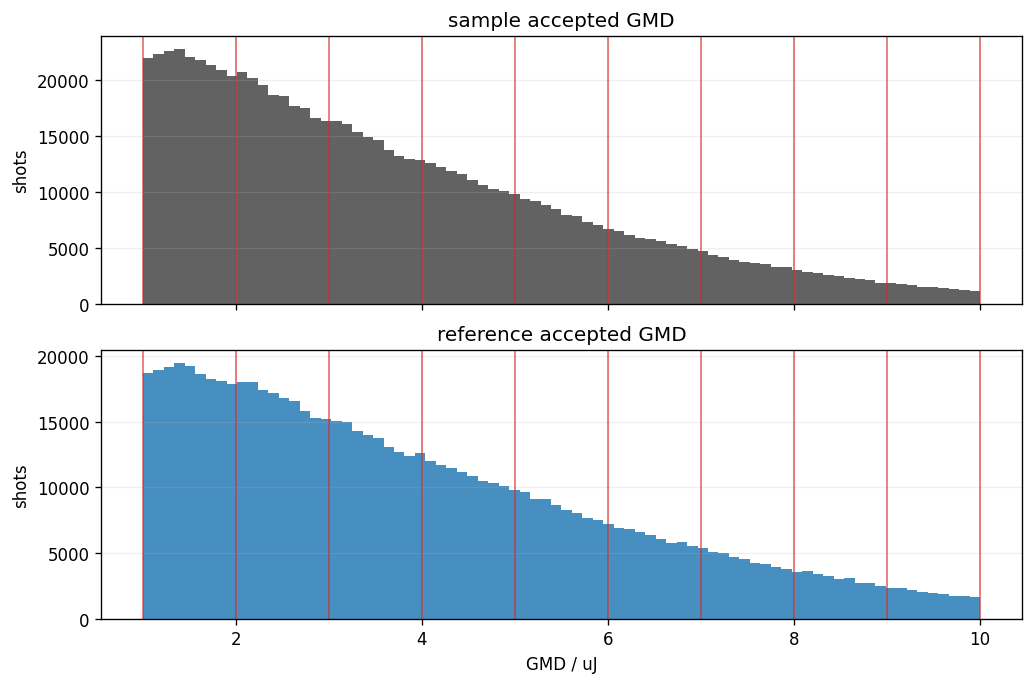

In [3]:
# Accepted-shot GMD audit for sample and no-sample reference.
fig, axes = gr.plot_accepted_gmd_audit(result, bins=80)
plt.show()

In [4]:
# Counts and mean-GMD diagnostics.
nominal_counts = gr.counts_table(result, axis="nominal")
converted_counts = gr.counts_table(result, axis="converted")

nominal_view = nominal_counts[np.isfinite(nominal_counts["absorbance"])].copy()
converted_view = converted_counts[np.isfinite(converted_counts["absorbance"])].copy()

display(nominal_view.head(40).style.format({
    "energy_eV": "{:.3f}",
    "sample_count": "{:.0f}",
    "reference_count": "{:.0f}",
    "sample_mean_gmd": "{:.3f}",
    "reference_mean_gmd": "{:.3f}",
    "sample_mean_vls": "{:.3g}",
    "reference_mean_vls": "{:.3g}",
    "absorbance": "{:.4f}",
}))

print(f"finite nominal cells: {len(nominal_view):,}")
print(f"finite converted cells: {len(converted_view):,}")

,axis,energy_eV,gmd_bin,gmd_label,sample_count,reference_count,sample_mean_gmd,reference_mean_gmd,sample_mean_vls,reference_mean_vls,absorbance
5,nominal,270.000,5,6-7) uJ; mean 6.5,1,4308,6.689,6.492,3.85e+03,1.24e+05,1.5062
9,nominal,270.500,0,1-2) uJ; mean 1.5,5393,8925,1.535,1.531,3.68e+04,2.85e+04,-0.1104
10,nominal,270.500,1,2-3) uJ; mean 2.5,6141,8908,2.494,2.474,5.78e+04,4.44e+04,-0.1148
11,nominal,270.500,2,3-4) uJ; mean 3.5,5601,5870,3.484,3.462,8.31e+04,6.28e+04,-0.1216
12,nominal,270.500,3,4-5) uJ; mean 4.5,4836,3776,4.486,4.459,1.1e+05,8.27e+04,-0.1223
13,nominal,270.500,4,5-6) uJ; mean 5.5,3754,2117,5.475,5.445,1.37e+05,1.03e+05,-0.1245
14,nominal,270.500,5,6-7) uJ; mean 6.5,2895,1129,6.482,6.436,1.62e+05,1.22e+05,-0.1228
15,nominal,270.500,6,7-8) uJ; mean 7.5,2095,536,7.483,7.465,1.88e+05,1.43e+05,-0.1203
16,nominal,270.500,7,8-9) uJ; mean 8.5,1540,304,8.474,8.455,2.12e+05,1.57e+05,-0.1299
17,nominal,270.500,8,9-10] uJ; mean 9.5,1062,140,9.474,9.431,2.36e+05,1.75e+05,-0.1297


finite nominal cells: 229
finite converted cells: 641


In [23]:
# Cell 5: plotting parameters only
# Difference direction: Delta A = A[DIFF_BIN_B] - A[DIFF_BIN_A]
DIFF_BIN_A = 1
DIFF_BIN_B = -1

SHOW_ERRORBARS = True
MATPLOTLIB_SHARE_X = True
MATPLOTLIB_XLIM = (271, 282)

PLOTLY_NOMINAL_XLIM = (271, 282)
PLOTLY_CONVERTED_XLIM = (271, 282)

NOMINAL_ABSORBANCE_YLIM = (-0.2,0.3)
CONVERTED_ABSORBANCE_YLIM = (-0.2,0.3)
NOMINAL_DELTA_YLIM = None
CONVERTED_DELTA_YLIM = None

gr.print_gmd_difference_summary(result, bin_a=DIFF_BIN_A, bin_b=DIFF_BIN_B)

Delta direction     : bin 8 - bin 1
bin A               : 2-3) uJ; mean 2.5
bin B               : 9-10] uJ; mean 9.5


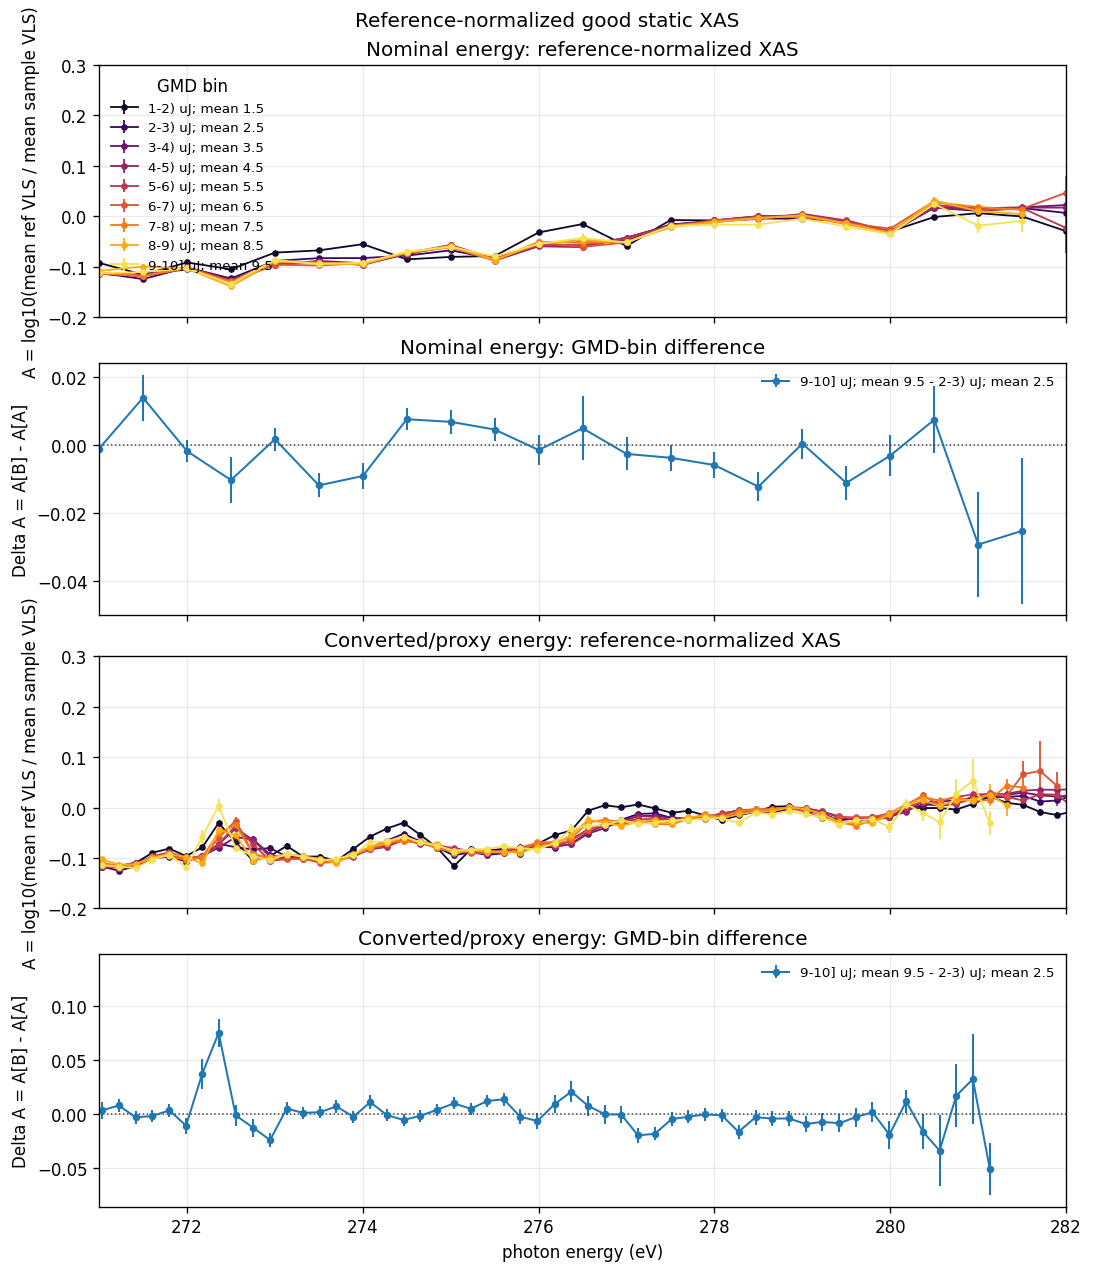

In [24]:
fig, axes = gr.plot_reference_xas_matplotlib(
    result,
    bin_a=DIFF_BIN_A,
    bin_b=DIFF_BIN_B,
    nominal_xlim=MATPLOTLIB_XLIM,
    converted_xlim=MATPLOTLIB_XLIM,
    absorbance_nominal_ylim=NOMINAL_ABSORBANCE_YLIM,
    delta_nominal_ylim=NOMINAL_DELTA_YLIM,
    absorbance_converted_ylim=CONVERTED_ABSORBANCE_YLIM,
    delta_converted_ylim=CONVERTED_DELTA_YLIM,
    share_xaxis=MATPLOTLIB_SHARE_X,
    show_errorbars=SHOW_ERRORBARS,
)
plt.show()

In [7]:
fig_plotly = gr.plot_reference_xas_plotly(
    result,
    bin_a=DIFF_BIN_A,
    bin_b=DIFF_BIN_B,
    nominal_xlim=PLOTLY_NOMINAL_XLIM,
    converted_xlim=PLOTLY_CONVERTED_XLIM,
    absorbance_nominal_ylim=NOMINAL_ABSORBANCE_YLIM,
    delta_nominal_ylim=NOMINAL_DELTA_YLIM,
    absorbance_converted_ylim=CONVERTED_ABSORBANCE_YLIM,
    delta_converted_ylim=CONVERTED_DELTA_YLIM,
    show_errorbars=SHOW_ERRORBARS,
)
fig_plotly

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'error_y': {'array': {'bdata': ('AAAAAAAA+H/J6SbRAyZgP/gWq8Q+81' ... '5saXg/gPYZcn1Fiz8aABPV6q6cPw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '1-2) uJ; mean 1.5',
              'line': {'color': '#10092d', 'width': 1.4},
              'marker': {'color': '#10092d', 'size': 5},
              'mode': 'lines+markers',
              'name': '1-2) uJ; mean 1.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAsHFAAAAAAAC4cUAAAAAAAMBxQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H/djHLgJEC8v6JureP6n7' ... 'Enc4O/jkBbv91juD94HU8G8fmovw=='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H+jAzaTSWJaP96MVHZVY1' ... 'PEvIE/cstnTvdWoD+LpFC9i/azPw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '2-3) uJ; mean 2.5',
              'line': {'color': '#3b0964', 'width': 1.4},
              'marker': {'color': '#3b0964', 'size': 5},
              'mode': 'lines+markers',
              'name': '2-3) uJ; mean 2.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAsHFAAAAAAAC4cUAAAAAAAMBxQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H/9X/H9Q2K9v3lNhd+Lor' ... 'EnYpE/SpmiDTRltz+kcHYnmrbHvw=='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H/nSuw+HARZP+cqcbP/vF' ... 'U6h44/fNOtcyRTtj8AAAAAAAD4fw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '3-4) uJ; mean 3.5',
              'line': {'color': '#67166e', 'width': 1.4},
              'marker': {'color': '#67166e', 'size': 5},
              'mode': 'lines+markers',
              'name': '3-4) uJ; mean 3.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAsHFAAAAAAAC4cUAAAAAAAMBxQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H8si+u3PCC/v9q8fgBKLb' ... 'YhKq0/YlO15n7Yzj8AAAAAAAD4fw=='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H+JC0VXXfBZPxLrSST7N1' ... '2cGps/AAAAAAAA+H8AAAAAAAD4fw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '4-5) uJ; mean 4.5',
              'line': {'color': '#922568', 'width': 1.4},
              'marker': {'color': '#922568', 'size': 5},
              'mode': 'lines+markers',
              'name': '4-5) uJ; mean 4.5',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('AAAAAADgcEAAAAAAAOhwQAAAAAAA8H' ... 'AAsHFAAAAAAAC4cUAAAAAAAMBxQA=='),
                    'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAA+H/PXepK4Eu/vzOif1J7Pb' ... '73yqk/AAAAAAAA+H8AAAAAAAD4fw=='),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'error_y': {'array': {'bdata': ('AAAAAAAA+H+DaZBhRSlcP/JuRZkaxF' ... 'AAAPh/AAAAAAAA+H8AAAAAAAD4fw=='),
                                    'dtype': 'f8'},
                          'type': 'data',
                          'visible': True},
              'legendgroup': '5-6) uJ; mean 5.5',
              'line': {'color': '#bc3754', 'width': 1.4},
              '

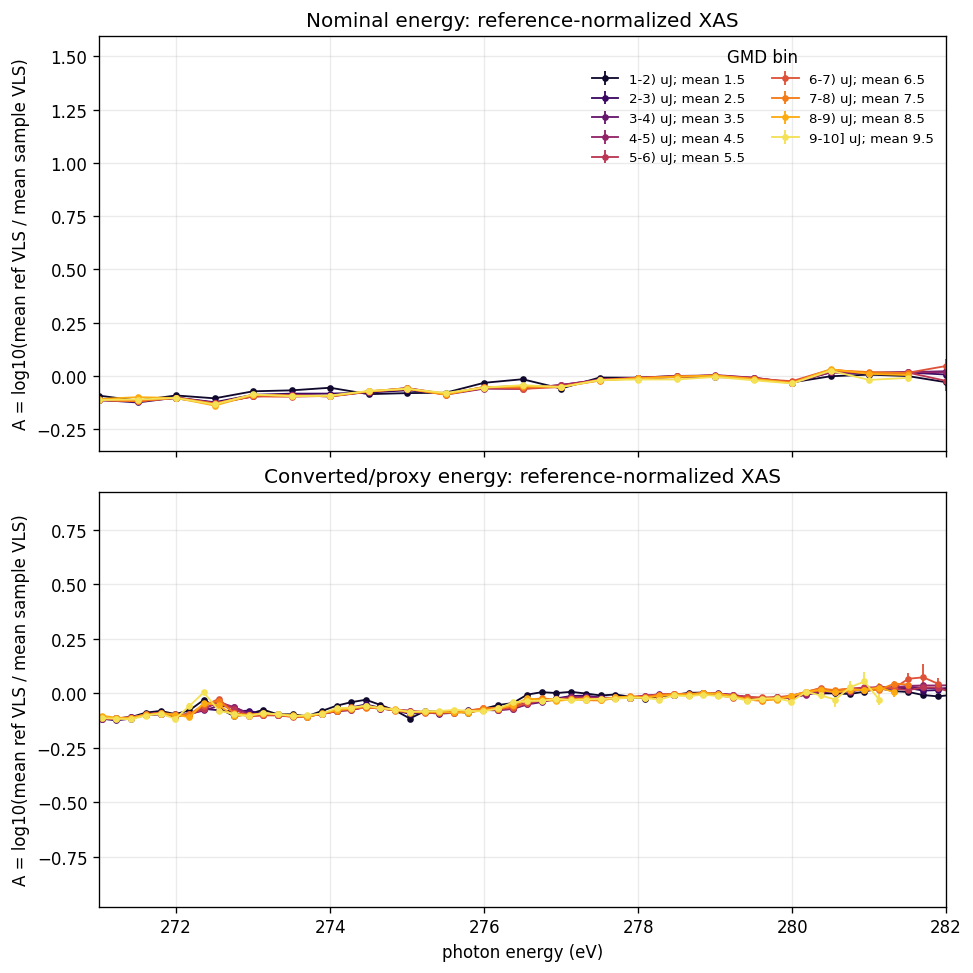

In [8]:
# XAS-only nominal/converted plot.
XAS_ONLY_XLIM = (271, 282)
XAS_ONLY_SHOW_ERRORBARS = True

fig, axes = plt.subplots(2, 1, figsize=(8, 8), sharex=True, constrained_layout=True)
colors = plt.cm.inferno(np.linspace(0.08, 0.92, len(result.gmd_labels)))

panels = [
    (axes[0], result.nominal, "Nominal energy: reference-normalized XAS", NOMINAL_ABSORBANCE_YLIM),
    (axes[1], result.converted, "Converted/proxy energy: reference-normalized XAS", CONVERTED_ABSORBANCE_YLIM),
]

for ax, binned, title, ylim in panels:
    order = gr.finite_x_order(binned.x)
    x = binned.x[order]
    y = binned.absorbance[order]
    err = binned.absorbance_sem[order]
    for ig, (label, color) in enumerate(zip(result.gmd_labels, colors)):
        keep = np.isfinite(x) & np.isfinite(y[:, ig])
        if not np.any(keep):
            continue
        if XAS_ONLY_SHOW_ERRORBARS:
            ax.errorbar(x[keep], y[keep, ig], yerr=err[keep, ig], marker="o", ms=3, lw=1.1, color=color, label=label)
        else:
            ax.plot(x[keep], y[keep, ig], marker="o", ms=3, lw=1.1, color=color, label=label)
    ax.set_title(title)
    ax.set_ylabel("A = log10(mean ref VLS / mean sample VLS)")
    ax.grid(alpha=0.25)
    if ylim is not None:
        ax.set_ylim(*ylim)

axes[0].legend(title="GMD bin", frameon=False, fontsize=8, ncol=2)
axes[1].set_xlabel("photon energy (eV)")
if XAS_ONLY_XLIM is not None:
    axes[1].set_xlim(*XAS_ONLY_XLIM)
plt.show()